# Training: SFT, two from-scratch DPO runs, and LoRA-DPO

Accelerator: GPU T4 x2. Every cell runs a command from the repository.

## Task 1: Repository and Kaggle setup

In [1]:
REPO_URL = 'https://github.com/syeddaniyalg/cs5326-pa2'

In [2]:
!git clone {REPO_URL} /kaggle/working/cs5326-pa2

Cloning into '/kaggle/working/cs5326-pa2'...
remote: Enumerating objects: 395, done.
remote: Counting objects: 100% (395/395), done.
remote: Compressing objects: 100% (172/172), done.
remote: Total 395 (delta 197), reused 395 (delta 197), pack-reused 0 (from 0)
Receiving objects: 100% (395/395), 1.11 MiB | 8.54 MiB/s, done.
Resolving deltas: 100% (197/197), done.


In [3]:
%cd /kaggle/working/cs5326-pa2

/kaggle/working/cs5326-pa2


In [4]:
!python -m pip uninstall -y -q torchao || true
!python -m pip install -q -r requirements.txt
!python -m pip install -q -e . --no-deps

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 92.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 25.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 945.8/945.8 kB 34.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 48.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 85.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requireme

In [5]:
!nvidia-smi
!python scripts/check_environment.py --require_two_gpus

Wed Oct 14 08:57:49 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   51C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [6]:
!PYTHONPATH=. python -m pytest -q tests

..................................................                       [100%]
50 passed in 2.42s


## Data preparation

In [7]:
!python scripts/prepare_data.py --task all

README.md: 3.90kB [00:00, 17.4MB/s]
data/train_sft-00000-of-00003-a3ecf92756(…): 100%|█| 244M/244M [00:01<00:00, 150
data/train_sft-00001-of-00003-0a1804bcb6(…): 100%|█| 244M/244M [00:01<00:00, 142
data/train_sft-00002-of-00003-ee46ed25cf(…): 100%|█| 244M/244M [00:01<00:00, 174
data/test_sft-00000-of-00001-f7dfac4afe5(…): 100%|█| 81.2M/81.2M [00:01<00:00, 5
data/train_gen-00000-of-00003-a6c9fb894b(…): 100%|█| 244M/244M [00:01<00:00, 204
data/train_gen-00001-of-00003-d6a0402e41(…): 100%|█| 243M/243M [00:06<00:00, 36.
data/train_gen-00002-of-00003-c0db75b92a(…): 100%|█| 243M/243M [00:01<00:00, 129
data/test_gen-00000-of-00001-3d4cd830914(…): 100%|█| 80.4M/80.4M [00:00<00:00, 1
Generating train_sft split: 100%|█| 207865/207865 [00:05<00:00, 38700.17 example
Generating test_sft split: 100%|█| 23110/23110 [00:00<00:00, 57626.43 examples/s
Generating train_gen split: 100%|█| 256032/256032 [00:03<00:00, 66764.59 example
Generating test_gen split: 100%|█| 28304/28304 [00:00<00:00, 71494.65 exa

## Task 3: Supervised fine-tuning

In [8]:
!python scripts/train_sft.py --config configs/sft.yaml --resume --skip_if_complete

tokenizer_config.json: 7.23kB [00:00, 18.7MB/s]
vocab.json: 2.78MB [00:00, 46.3MB/s]
merges.txt: 1.67MB [00:00, 133MB/s]
tokenizer.json: 7.03MB [00:00, 186MB/s]
config.json: 100%|█████████████████████████████| 681/681 [00:00<00:00, 3.87MB/s]
`torch_dtype` is deprecated! Use `dtype` instead!
model.safetensors: 100%|██████████████████████| 988M/988M [00:05<00:00, 186MB/s]
generation_config.json: 100%|███████████████████| 138/138 [00:00<00:00, 955kB/s]
SFT train:  11%| | 1600/15000 [08:34<1:14:47,  2.99it/s, loss=1.366, grad_norm=4
SFT val: 100%|████████████████████████████████| 250/250 [00:48<00:00,  5.26it/s]
SFT train:  21%|▏| 3200/15000 [18:45<57:12,  3.44it/s, loss=1.381, grad_norm=4.6
SFT val: 100%|████████████████████████████████| 250/250 [00:48<00:00,  5.30it/s]
SFT train:  32%|▎| 4800/15000 [28:47<54:35,  3.11it/s, loss=1.398, grad_norm=5.0
SFT val: 100%|████████████████████████████████| 250/250 [00:47<00:00,  5.32it/s]
SFT train:  43%|▍| 6400/15000 [39:23<42:37,  3.36it/s, loss=

In [9]:
!zip -qr /kaggle/working/sft_run_outputs.zip outputs/sft outputs/environment.json data/processed/manifest.json

## Task 4: From-scratch DPO

In [10]:
!python scripts/train_dpo.py --config configs/dpo_hh.yaml --resume --skip_if_complete

The tokenizer you are loading from 'outputs/sft/best' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.
`torch_dtype` is deprecated! Use `dtype` instead!
DPO dpo_hh:   0%|                            | 32/15000 [00:06<46:39,  5.35it/s]/kaggle/working/cs5326-pa2/alignment/dpo.py:121: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  self.scheduler.step()
DPO dpo_hh:  11%| | 1600/15000 [05:41<47:16,  4.72it/s, loss=0.6764, acc

In [11]:
!python scripts/train_dpo.py --config configs/dpo_uf.yaml --resume --skip_if_complete

The tokenizer you are loading from 'outputs/sft/best' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.
`torch_dtype` is deprecated! Use `dtype` instead!
DPO dpo_uf:   0%|                          | 32/15000 [00:11<1:34:44,  2.63it/s]/kaggle/working/cs5326-pa2/alignment/dpo.py:121: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  self.scheduler.step()
DPO dpo_uf:  11%| | 1600/15000 [09:23<1:19:33,  2.81it/s, loss=0.6333, a

In [12]:
!zip -qr /kaggle/working/dpo_run_outputs.zip outputs/dpo_hh outputs/dpo_uf

## Task 5: TRL DPOTrainer with LoRA

In [13]:
!CUDA_VISIBLE_DEVICES=0 python scripts/train_lora_dpo.py \
    --config configs/lora_dpo.yaml \
    --resume \
    --skip_if_complete

tokenizer_config.json: 3.76kB [00:00, 13.6MB/s]
vocab.json: 801kB [00:00, 16.6MB/s]
merges.txt: 466kB [00:00, 67.3MB/s]
tokenizer.json: 2.10MB [00:00, 99.6MB/s]
config.json: 100%|█████████████████████████████| 846/846 [00:00<00:00, 8.05MB/s]
`torch_dtype` is deprecated! Use `dtype` instead!
model.safetensors: 100%|██████████████████████| 724M/724M [00:02<00:00, 322MB/s]
Tokenizing train dataset: 100%|███████| 198/198 [00:00<00:00, 712.16 examples/s]
Dropping fully truncated examples from train dataset: 100%|█| 198/198 [00:00<00:
Tokenizing eval dataset: 100%|██████████| 22/22 [00:00<00:00, 659.04 examples/s]
Dropping fully truncated examples from eval dataset: 100%|█| 22/22 [00:00<00:00,
LoRA DPO:   3%| | 1/39 [00:08<05:08,  8.12s/it, loss=0.6931, accuracy=0, margin={'loss': 0.6931, 'grad_norm': 1.1681938171386719, 'learning_rate': 0.0, 'entropy': 2.2364070415496826, 'num_tokens': 3107.0, 'logits/chosen': 0.7972789165356193, 'logits/rejected': 0.23830050384241777, 'mean_token_accuracy'

## Training figures and tables

In [14]:
!python scripts/make_figures.py --output_root outputs
!python scripts/make_tables.py --output_root outputs


Training figures: 100%|##########| 4/4 [00:10<00:00,  2.55s/it]
No evaluation summaries found.
Saved config_table (4 rows)
Saved deviations_table (1 rows)
Saved training_summary_table (4 rows)
Skipping results_table: no rows
Skipping category_table: no rows
Skipping text_stats_table: no rows
Skipping examples_table: no rows


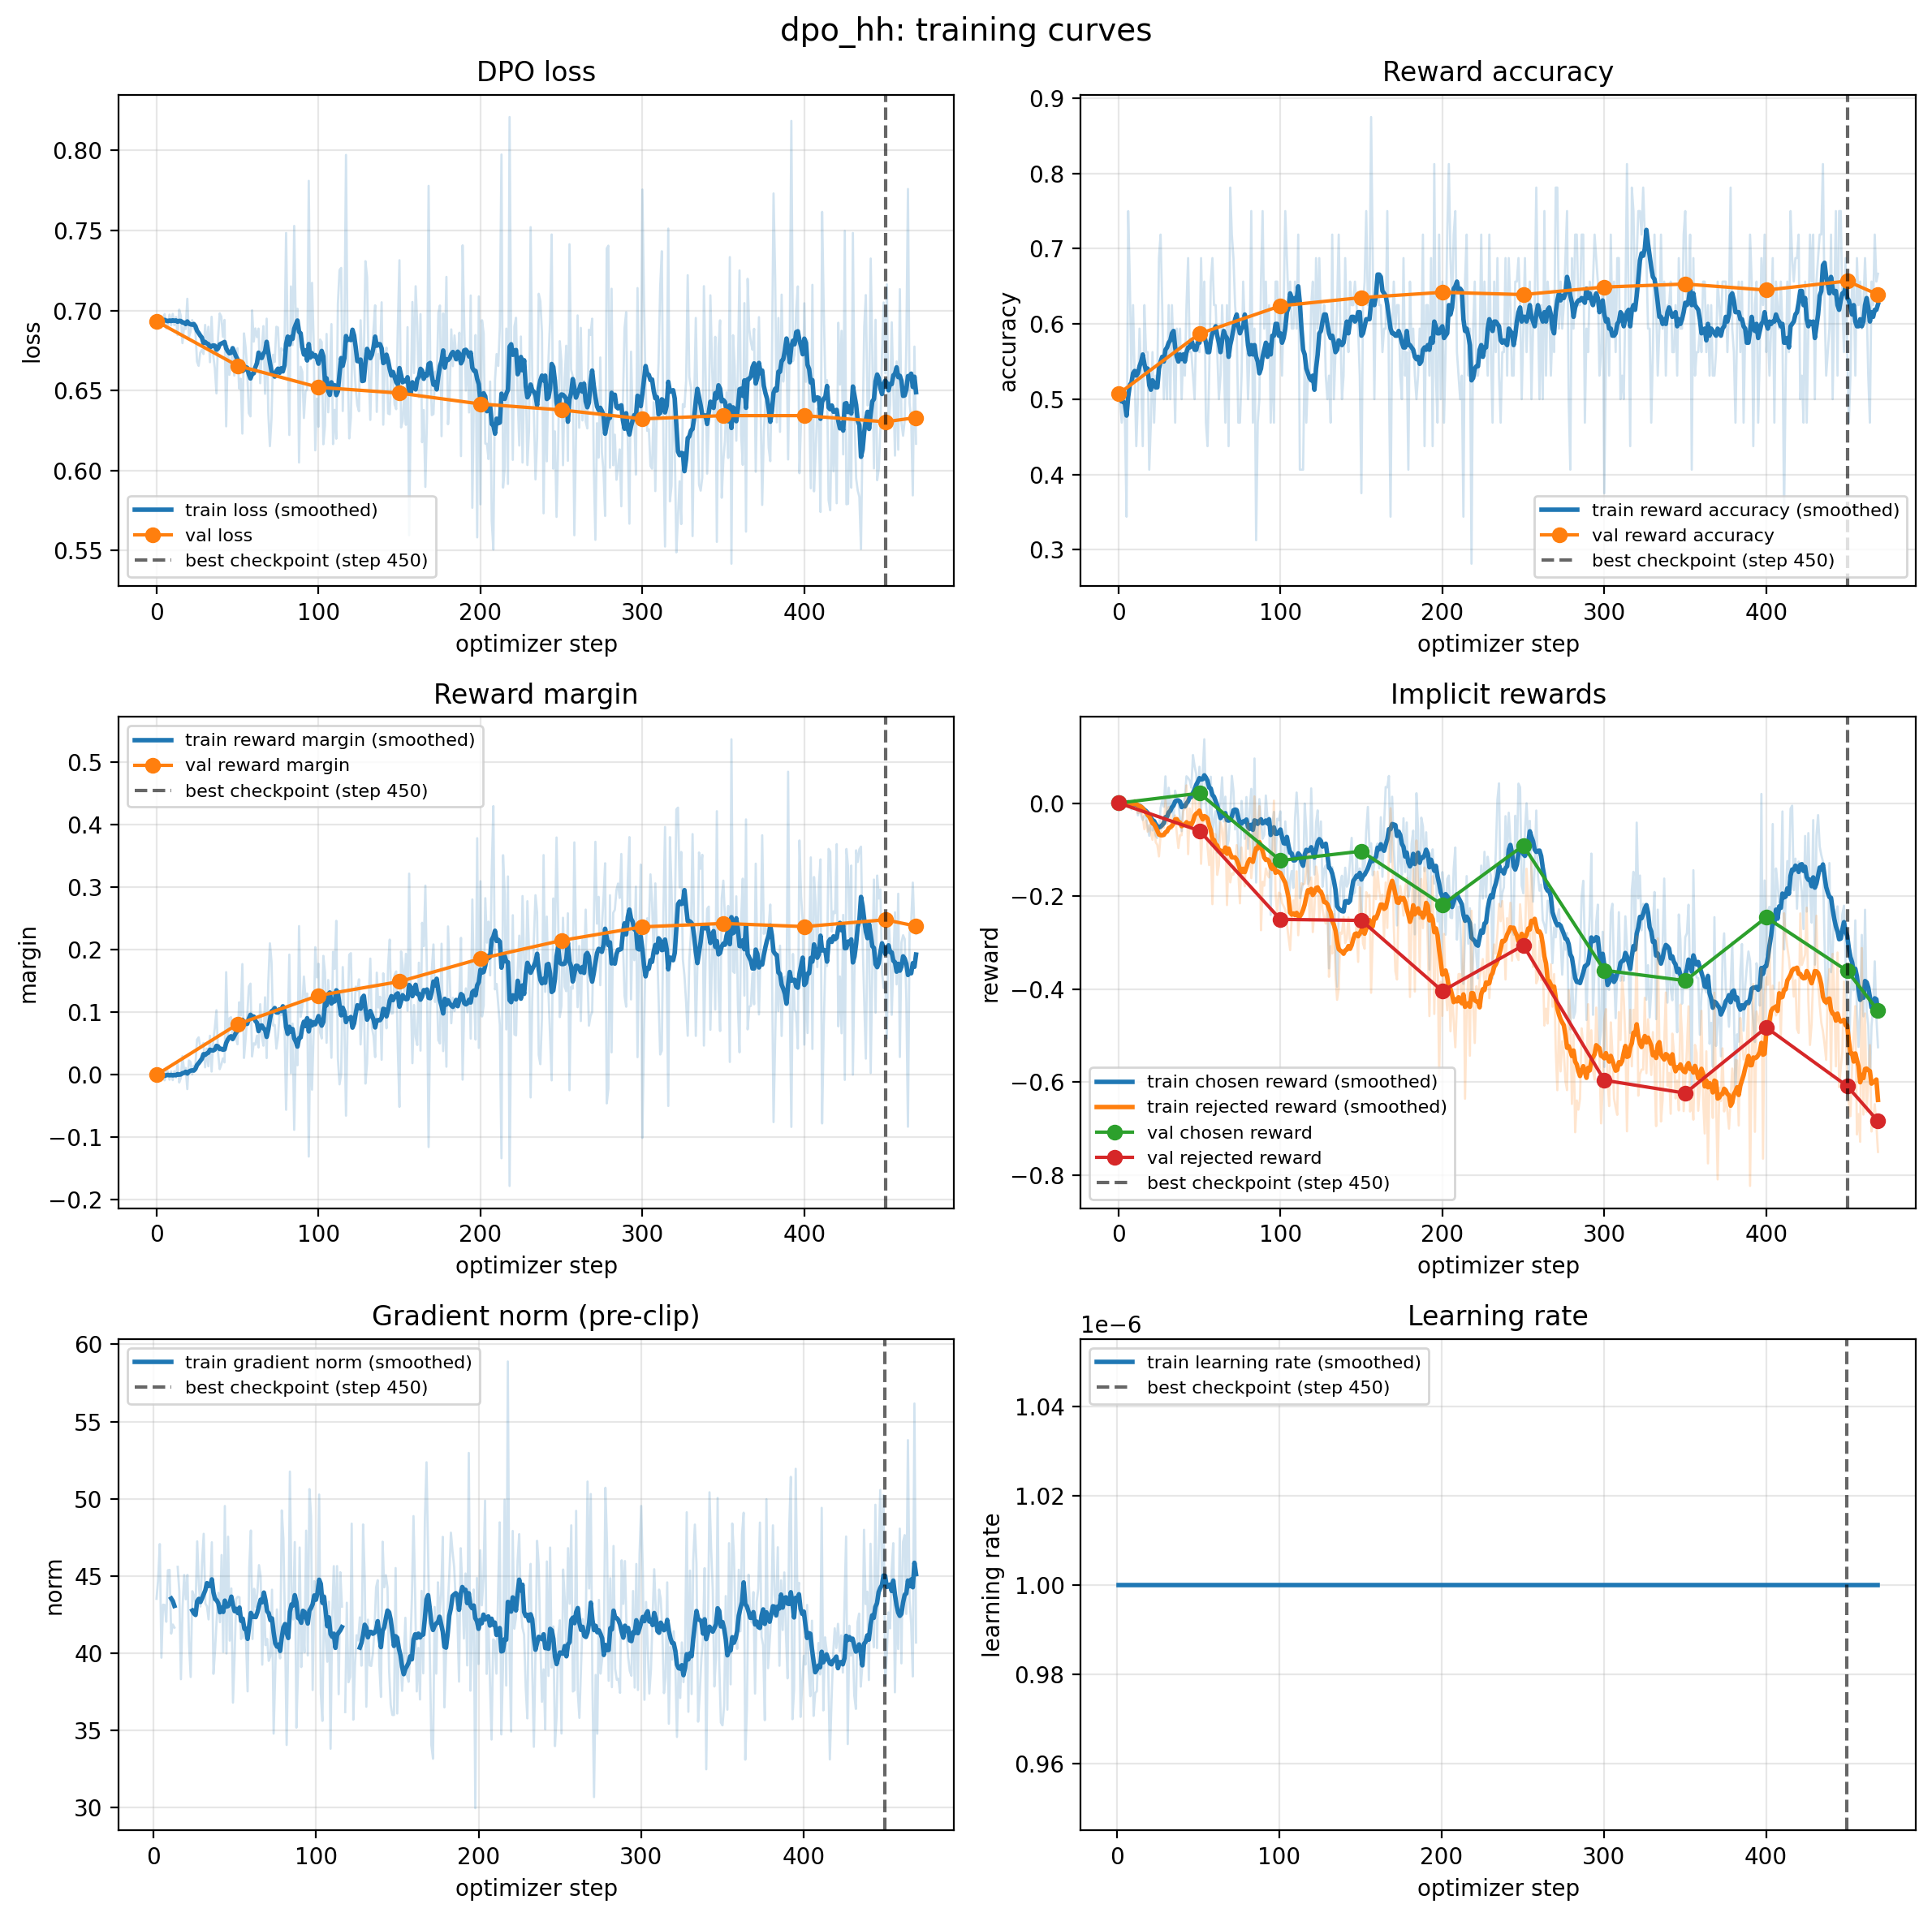

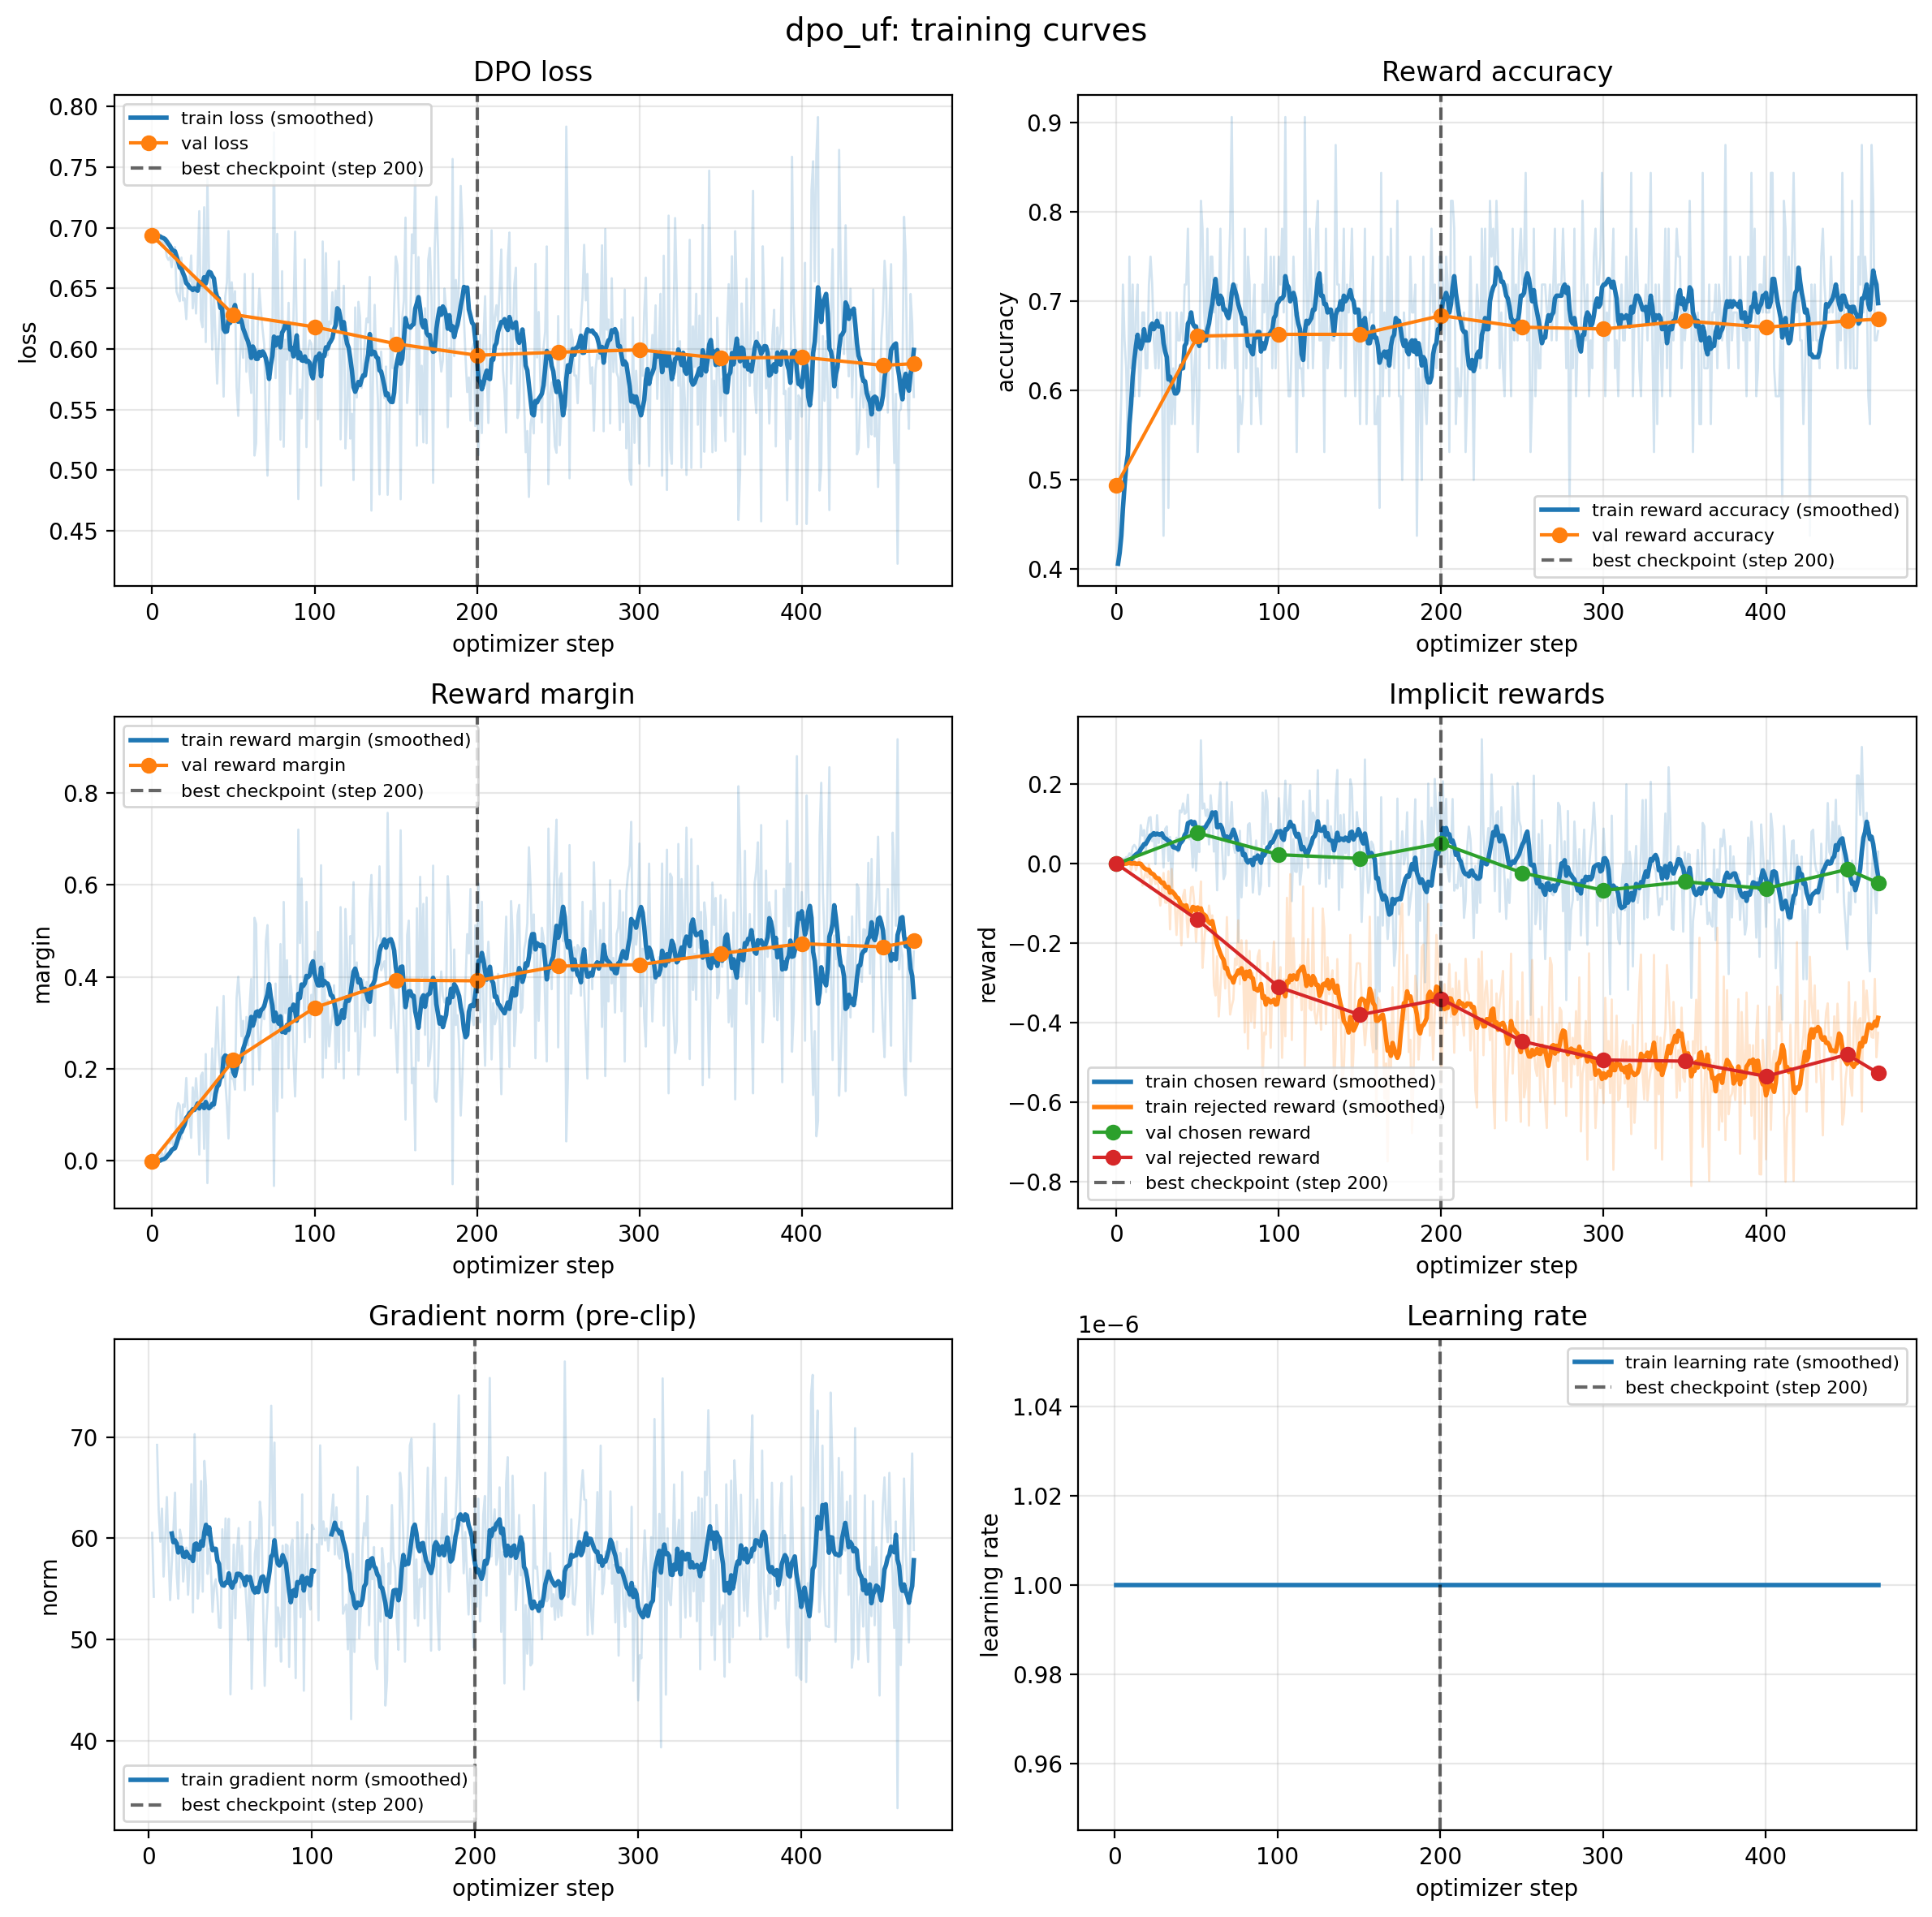

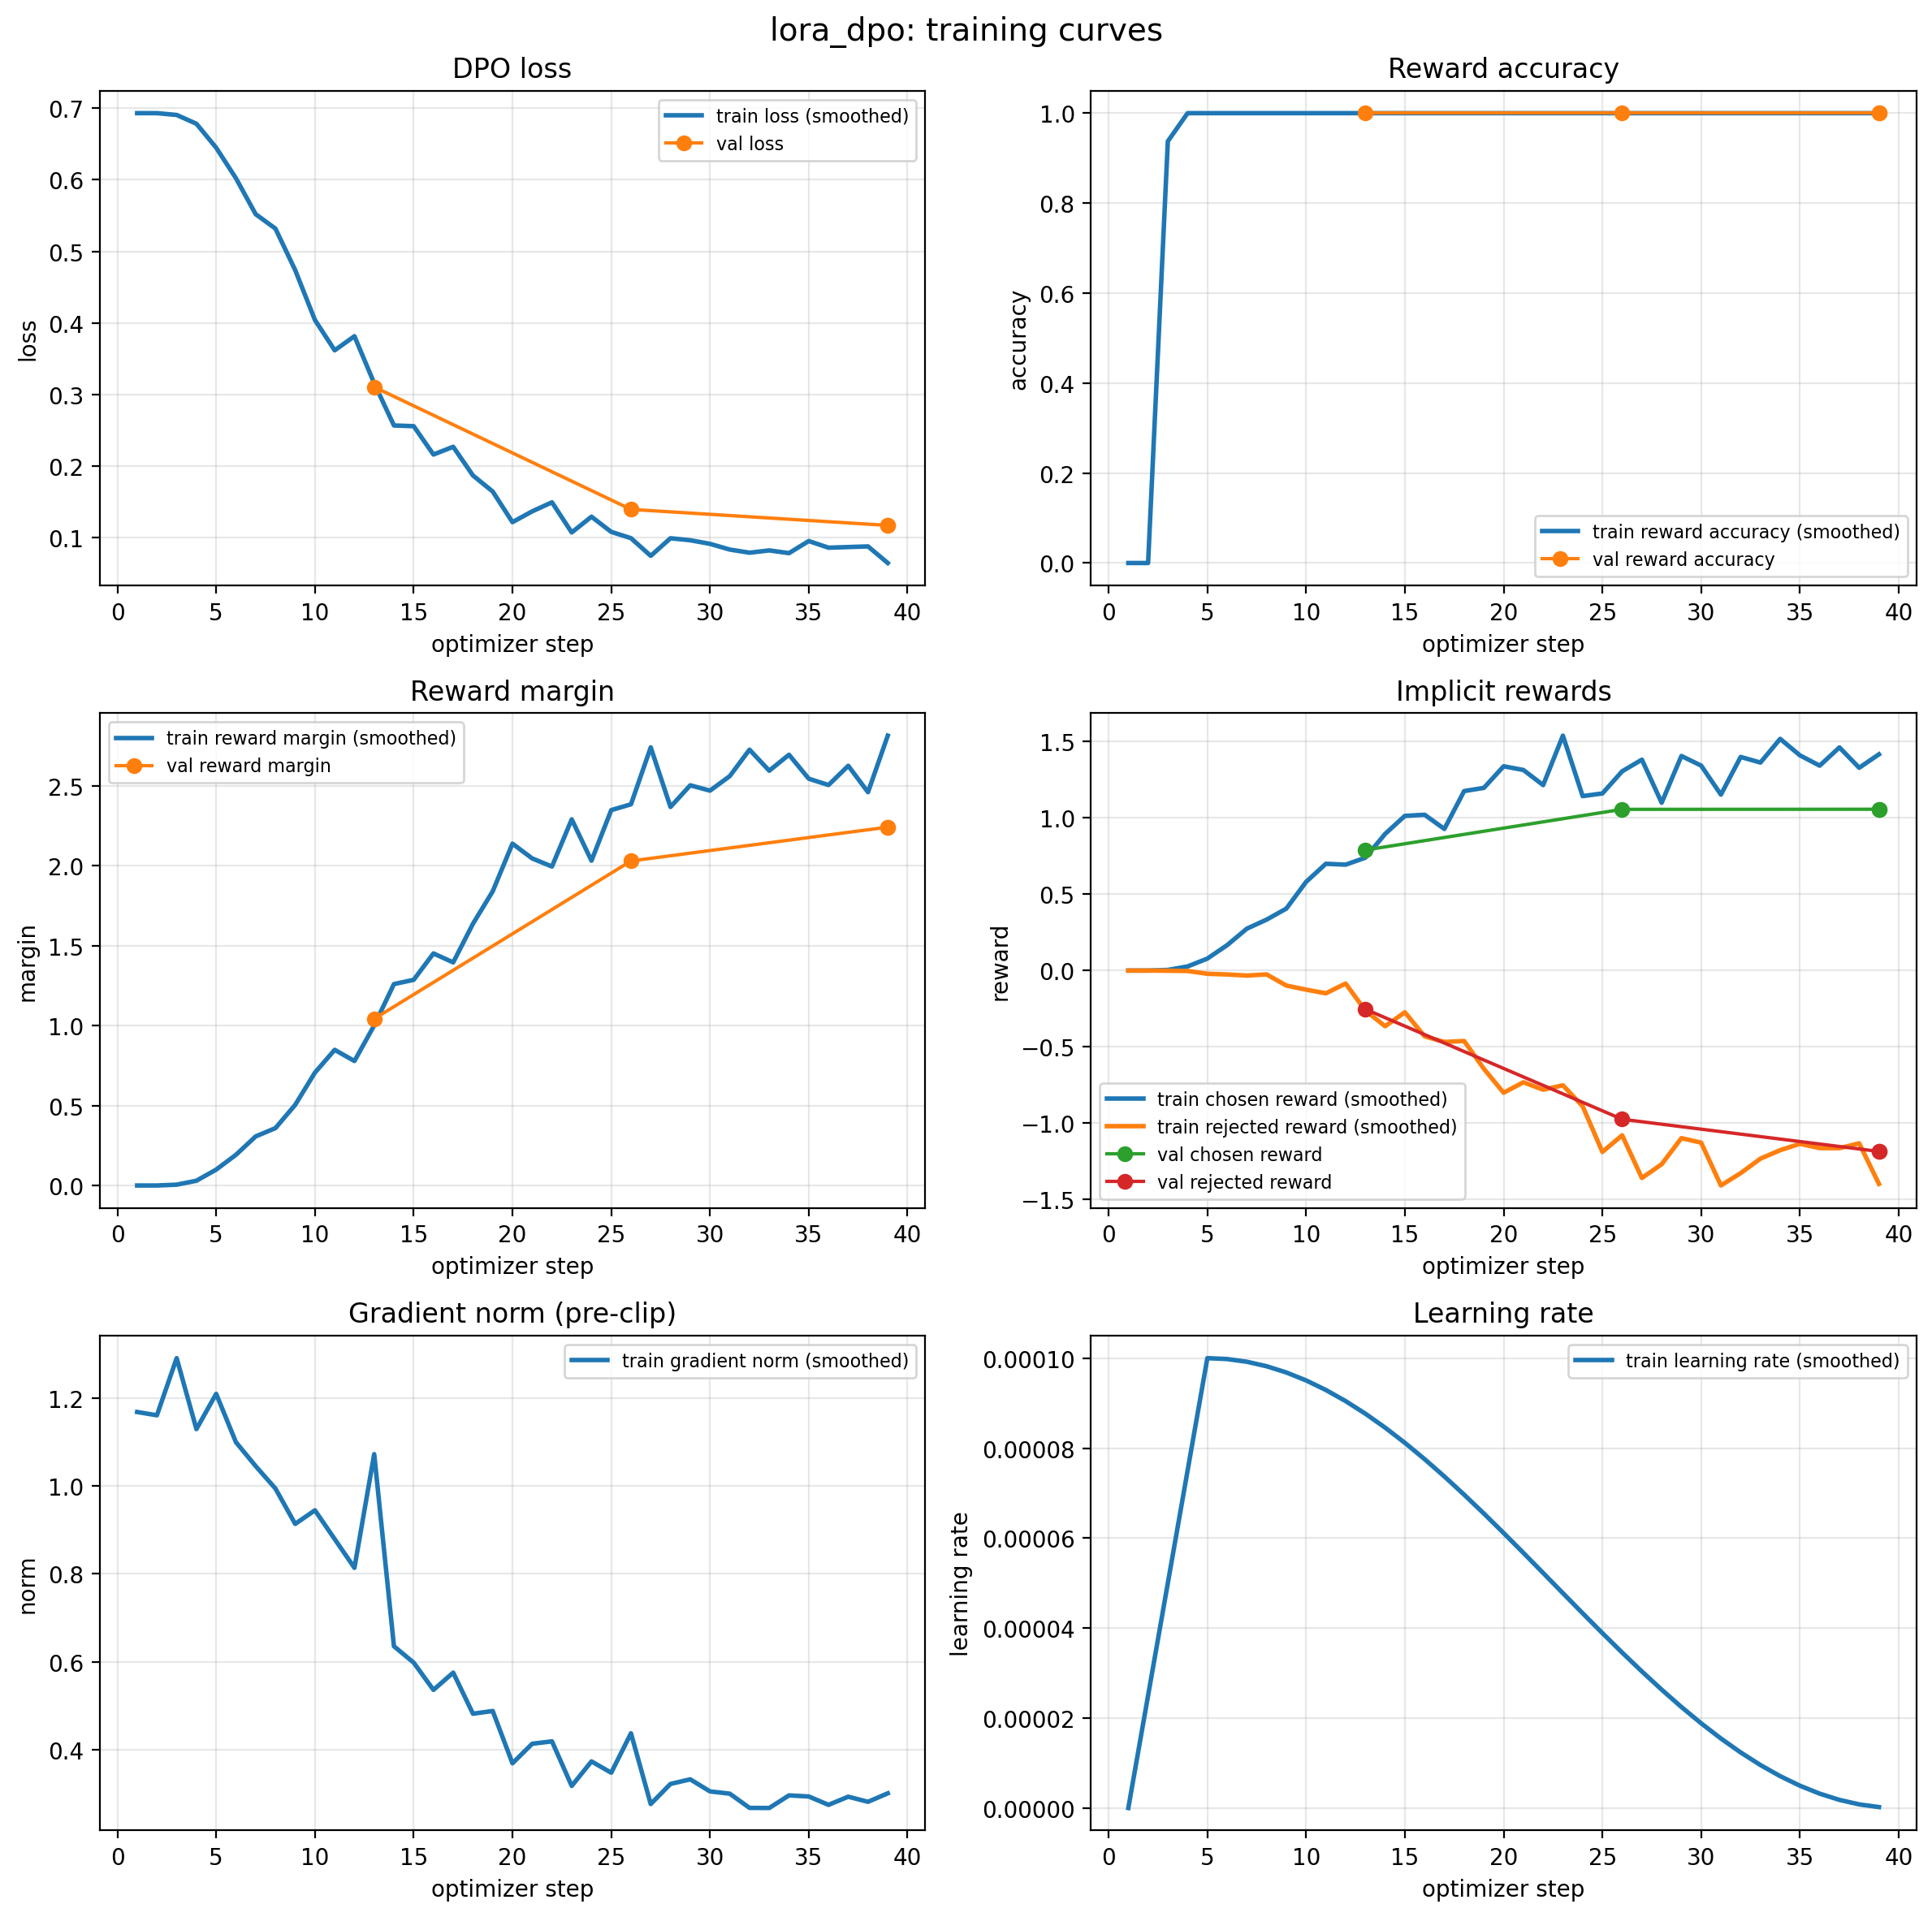

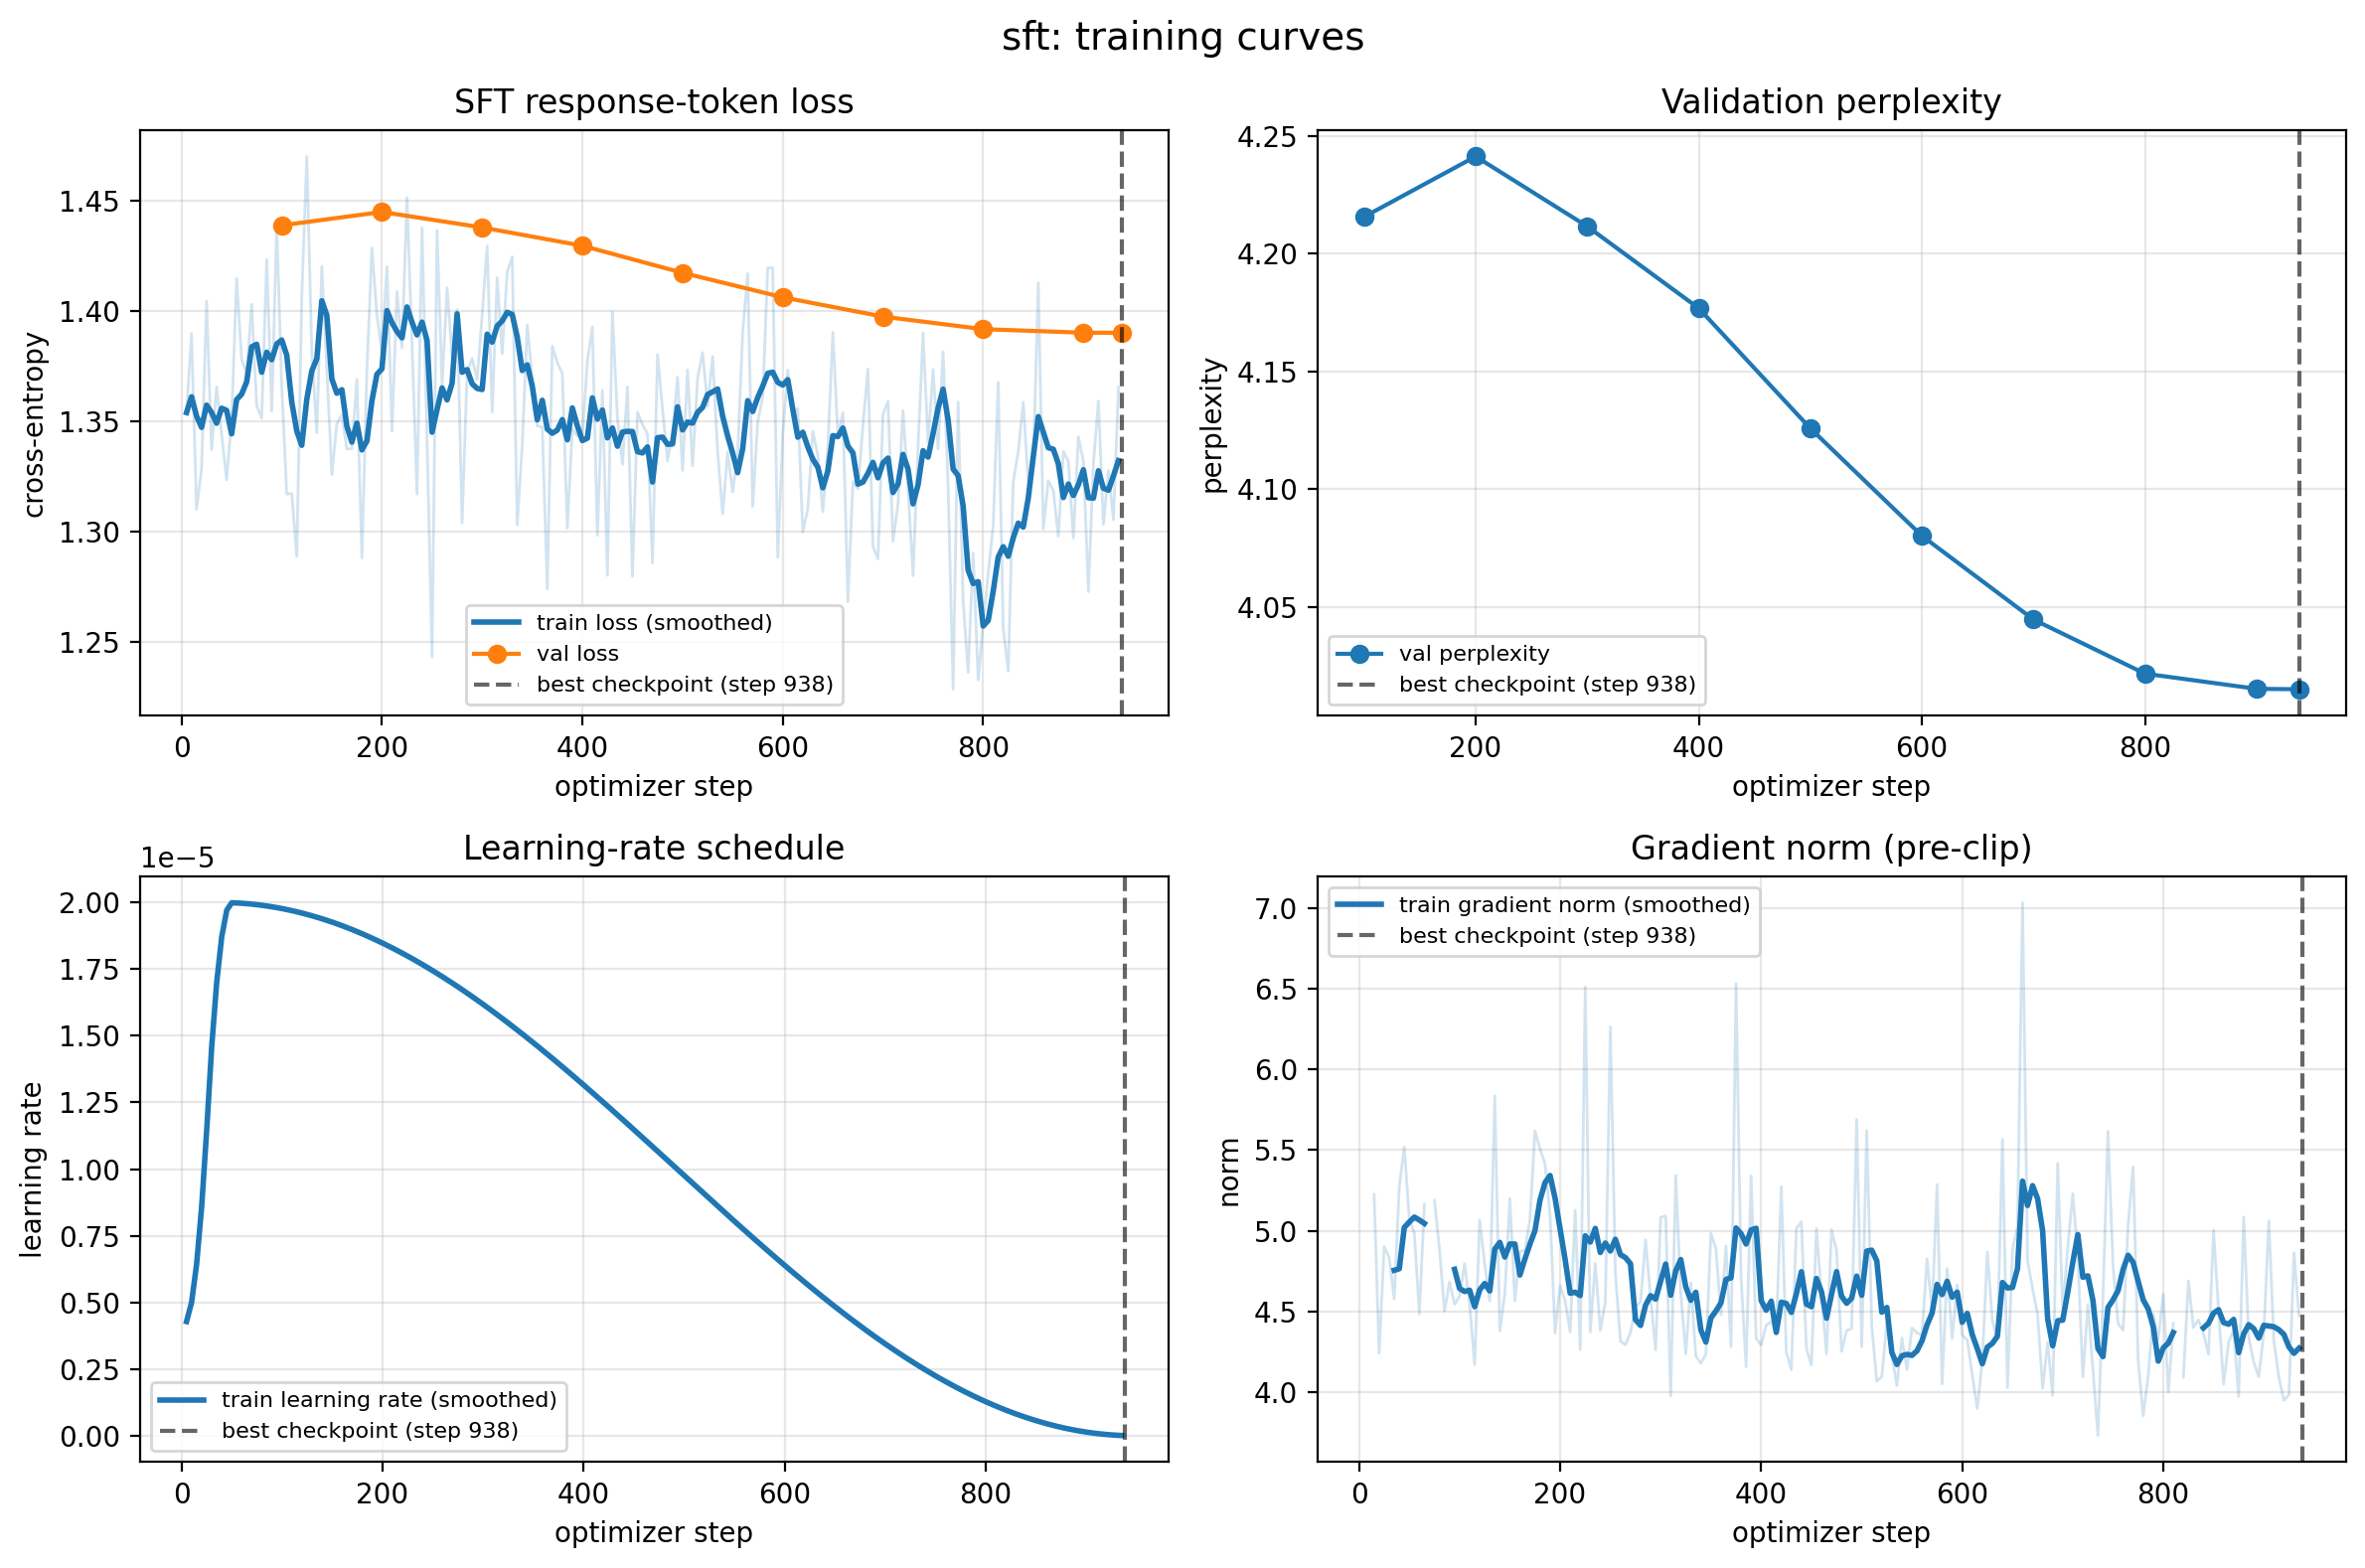

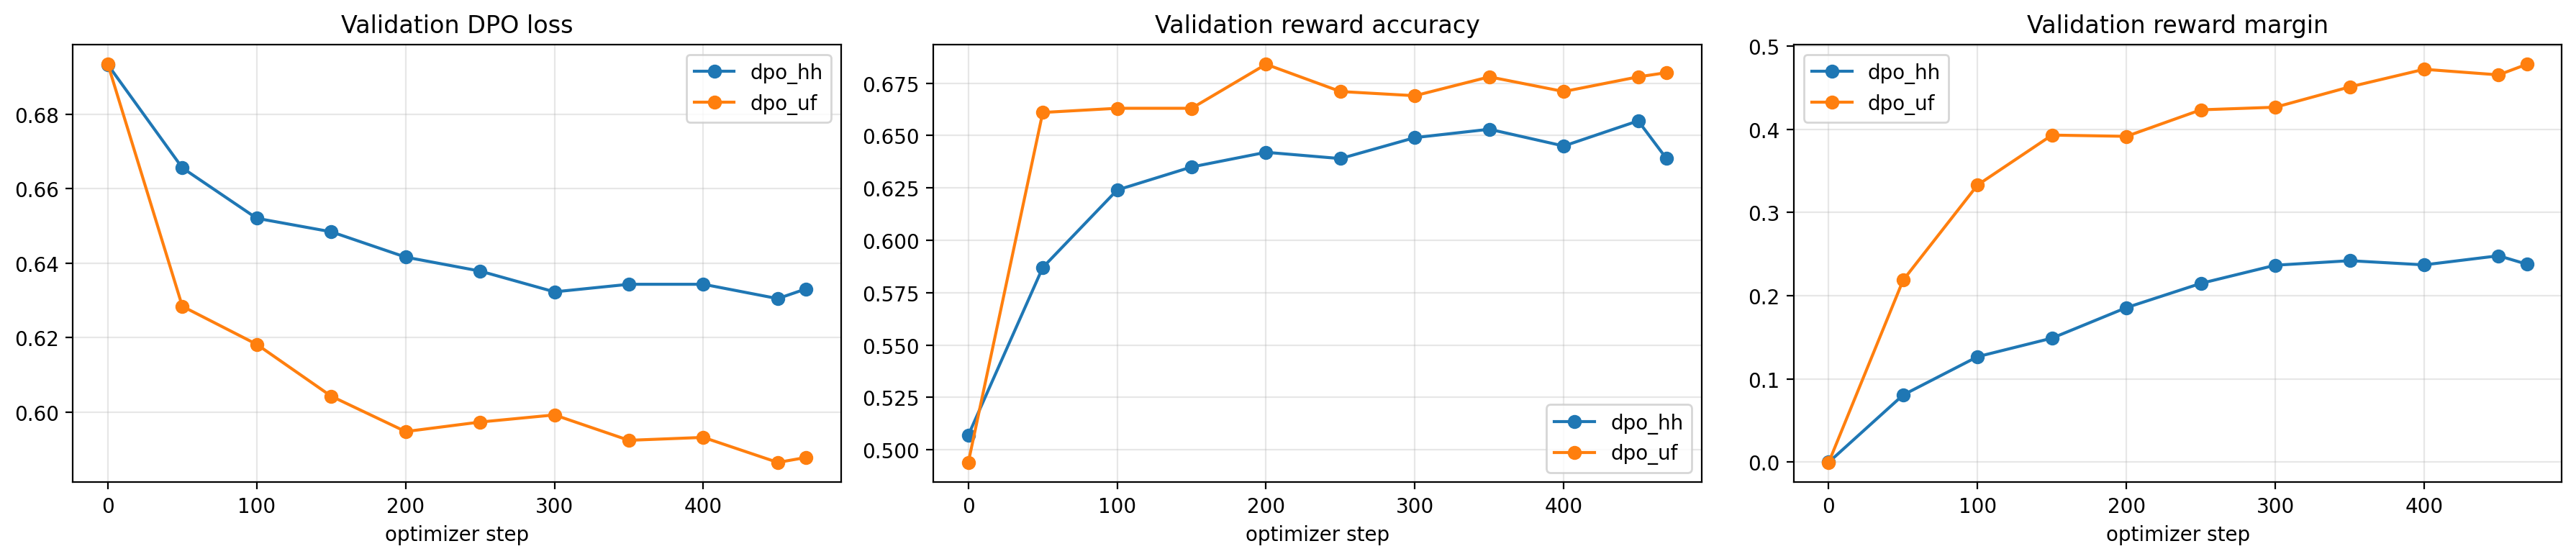

| run | trainable parameters | optimizer | peak LR | scheduler | warmup | weight decay | grad clip | per-device batch | grad accumulation | effective batch | precision | max length | epochs | optimizer steps | seed | beta | reference checkpoint | decoding |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| SFT | full fine-tuning | adamw | 2e-05 | cosine | 0.03 | 0.1 | 1 | 2 | 16 | 32 | fp32 weights, fp16 autocast, GradScaler | 512 | 1 | 938 | 42 | - | - |  |
| HH-RLHF DPO | full fine-tuning | adamw | 1e-06 | constant | 0 | 0 | 1 | 1 | 32 | 32 | fp32 weights, fp16 autocast, GradScaler | 512 | 1 | 469 | 42 | 0.1 | outputs/sft/best |  |
| UltraFeedback DPO | full fine-tuning | adamw | 1e-06 | constant | 0 | 0 | 1 | 1 | 32 | 32 | fp32 weights, fp16 autocast, GradScaler | 512 | 1 | 469 | 42 | 0.1 | outputs/sft/best |  |
| LoRA-DPO | LoRA r=16, alpha=32, dropout=0.05, targets=q_proj/k_proj/v_proj/o_proj/gate_proj/up_proj/down_proj | adamw_torch | 0.0001 | cosine | 0.1 | 0 | 1 | 4 | 4 | 16 | fp32 weights, fp16 AMP | 512 | 3 |  | 42 | 0.1 | base model with adapter disabled |  |


| run | parameter | guide value | used value | type | reason and evidence |
| --- | --- | --- | --- | --- | --- |
| all | none | - | - | - | No deviations from the guide configuration. |


| run | train examples | val examples | optimizer steps | best step | train minutes | best val loss | final val loss | best val accuracy | best val margin | final val accuracy | final val margin | trainable parameters |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| SFT | 30000 | 1000 | 938 | 938 | 100.4 | 1.39 | 1.39 |  |  |  |  |  |
| HH-RLHF DPO | 15000 | 1000 | 469 | 450 | 71.4 | 0.6305 | 0.6331 | 0.657 | 0.2479 | 0.639 | 0.2378 |  |
| UltraFeedback DPO | 15000 | 1000 | 469 | 200 | 114.2 | 0.5948 | 0.5879 | 0.684 | 0.3914 | 0.68 | 0.478 |  |
| LoRA-DPO | 198 | 22 |  |  | 1.8 |  | 0.1171 |  |  | 1 | 2.242 | 8683520 |


In [15]:
from pathlib import Path
from IPython.display import Image, Markdown, display

for path in sorted(Path('outputs/figures').glob('*_training_curves.png')):
    display(Image(filename=str(path)))

for path in sorted(Path('outputs/figures').glob('dpo_validation_comparison.png')):
    display(Image(filename=str(path)))

for stem in ['config_table', 'deviations_table', 'training_summary_table']:
    path = Path('outputs/tables') / f'{stem}.md'
    if path.exists():
        display(Markdown(path.read_text()))

In [16]:
!zip -qr /kaggle/working/lora_and_report_outputs.zip outputs/lora_dpo outputs/figures outputs/tables